In [1]:
import argparse, hashlib, json, math, os, sys, time, warnings
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize_scalar, nnls

In [2]:
T0, H, T, NS = 100, 43, 143, 45
O_MIN = 40                                # earliest placebo origin used by DiD / synthetic-control scales
TRUE_EFFECT, BUSINESS_SHIFT = 0.03, 0.05
Z, NOMINAL, HAC_LAG = 1.96, 0.95, 4
SCEN = ["none", "common5", "A_treated_only", "B_store_sizes", "C_gradual", "D_leak", "D2_leak_shift"]
SCEN_LABEL = {"none": "No shift", "common5": "5% common shift", "A_treated_only": "A: treated only",
              "B_store_sizes": "B: size per store", "C_gradual": "C: slow gradual",
              "D_leak": "D: control leakage", "D2_leak_shift": "D2: leakage + 5% shift"}
ORIGINAL = ["none", "common5"]          # the only scenarios used for calibration
LAMBDA_GRID = [0, 0.25, 0.5, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500]
K_GRID = [1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 9, 10, 12, 15, 16, 20, 30, 50, 100]
SHIFT_SIZES = [0.02, 0.03, 0.05, 0.08, 0.10]
POOL_K = (1, 3, 5, 10)
POOL_DRAWS = 6
N_CAL, N_SPLITS, SPLIT_SEED, N_BOOT = 22, 20, 0, 2000
DATASETS = {   # name: (T0, H, NS, O_MIN)
    "walmart": (100, 43, 45, 40),
    "dmart": (75, 30, 45, 30),
}


def configure(name):
    """Set the panel geometry for a dataset. Everything downstream reads these module globals."""
    global T0, H, T, NS, N_CAL, O_MIN, _SUMSQ
    T0, H, NS, O_MIN = DATASETS[name]
    T = T0 + H; N_CAL = NS // 2
    _SUMSQ = sum((H - j + 1) ** 2 for j in range(2, H + 1))

METHODS = ["standard", "bsts_control", "bsts_best_control", "fixed_k", "break_aware", "fixed_equal_width",
           "conformal_scaled", "conformal_abs", "did_best", "did_random", "synthetic"]
METHOD_LABEL = {"standard": "Standard BSTS", "bsts_control": "BSTS with control (random control)",
                "bsts_best_control": "BSTS with best control", "fixed_k": "Fixed widening (selected k)",
                "break_aware": "Break-aware (selected lambda)", "fixed_equal_width": "Fixed widening at break-aware width",
                "conformal_scaled": "Conformal (scaled)", "conformal_abs": "Conformal (absolute)",
                "did_best": "DiD, best control", "did_random": "DiD, random control", "synthetic": "Synthetic control",
                "bsts_control_widened": "BSTS with control, widened (k on calibration)",
                "bsts_control_at_ba_width": "BSTS with control at break-aware width"}

In [3]:
def _need(path, what):
    if path is None or not os.path.isfile(path):
        raise SystemExit(f"ERROR: {path} not found. The real {what} file is required; stopping. "
                         f"Use --smoke-test only to test the code.")


def load_walmart(path):
    _need(path,"/content/Walmart_Sales.csv" )
    df = pd.read_csv("/content/Walmart_Sales.csv")
    missing = [c for c in ("Store", "Date", "Weekly_Sales") if c not in df.columns]
    if missing:
        raise SystemExit(f"ERROR: {path} lacks columns {missing}; it has {list(df.columns)}")
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    df = df.dropna(subset=["Date", "Store", "Weekly_Sales"])
    wide = df.pivot_table(index="Store", columns="Date", values="Weekly_Sales", aggfunc="mean").sort_index(axis=1)
    wide = wide.iloc[:, :T]
    if wide.shape != (NS, T) or wide.isna().any().any():
        raise SystemExit(f"ERROR: expected a complete {NS} x {T} panel, got {wide.shape} "
                         f"with {int(wide.isna().sum().sum())} missing cells.")
    sha = hashlib.sha256(open(path, "rb").read()).hexdigest()
    return wide.values.astype(float), pd.DatetimeIndex(wide.columns), list(wide.index), sha


def load_dmart(path, group_seed=2024):
    """DMart has no store column: build NS pseudo-units by randomly grouping the customer names (fixed seed)."""
    _need(path, "/content/DMart_sample_data.csv")
    df = pd.read_csv("/content/DMart_sample_data.csv", usecols=["Date", "Total", "FullName"])
    dt = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    day = dt.dt.normalize()
    df = df.assign(day=day, week=day - pd.to_timedelta(dt.dt.dayofweek, unit="D")).dropna(subset=["week"])
    names = np.array(sorted(df["FullName"].unique()))
    grp = dict(zip(names, np.random.default_rng(group_seed).permutation(len(names)) % NS))
    df["unit"] = df["FullName"].map(grp)
    full = df.groupby("week")["day"].nunique(); full = full[full == 7].index          # complete Mon-Sun weeks only
    wide = df[df.week.isin(full)].pivot_table(index="unit", columns="week", values="Total", aggfunc="sum").sort_index(axis=1)
    if wide.shape != (NS, T) or wide.isna().any().any():
        raise SystemExit(f"ERROR: expected a complete {NS} x {T} DMart panel, got {wide.shape} "
                         f"with {int(wide.isna().sum().sum())} missing cells.")
    sha = hashlib.sha256(open(path, "rb").read()).hexdigest()
    return wide.values.astype(float), pd.DatetimeIndex(wide.columns), list(wide.index), sha


def synthetic_panel(seed=7):
    """CODE-TEST ONLY. Weekly panel with trend, annual season, holidays, a common macro factor and noise."""
    rng = np.random.default_rng(seed)
    t = np.arange(T)
    macro = np.cumsum(rng.normal(0, .004, T))
    Y = np.empty((NS, T))
    for i in range(NS):
        scale = rng.uniform(.6e6, 2.2e6)
        season = 1 + rng.uniform(.05, .15) * np.sin(2 * np.pi * (t - rng.uniform(0, 52)) / 52)
        hol = 1 + .25 * np.isin(t % 52, [46, 47, 51])
        Y[i] = scale * season * hol * np.exp(rng.uniform(-.0005, .001) * t + macro + rng.normal(0, .03, T))
    return Y, pd.date_range("2010-02-05", periods=T, freq="7D"), list(range(1, NS + 1)), "SYNTHETIC"

In [4]:
def nw_lrv(e, lags=HAC_LAG):
    e = np.asarray(e, float); e = e - e.mean(); n = len(e)
    s = e @ e / n
    for l in range(1, lags + 1):
        s += 2 * (1 - l / (lags + 1)) * (e[l:] @ e[:-l] / n)
    return float(max(s, 0.0))


def yoy_diag(c):
    """Change in mean year-over-year log growth after the intervention; z = S / HAC se."""
    lr = np.log(c[52:]) - np.log(c[:-52])
    pre, post = lr[:T0 - 52], lr[T0 - 52:]
    S = float(post.mean() - pre.mean())
    se = math.sqrt(nw_lrv(post) / len(post) + nw_lrv(pre) / len(pre))
    return dict(z=S / se if se > 0 else 0.0, S=S, rel=float(np.expm1(S)), hac_se=se)


def _design(t):
    t = np.asarray(t, float)
    return np.column_stack([np.ones(len(t)), t, np.sin(2 * np.pi * t / 52), np.cos(2 * np.pi * t / 52)])


def legacy_diag(c):
    t = np.arange(len(c))
    beta, *_ = np.linalg.lstsq(_design(t[:T0]), c[:T0], rcond=None)
    post = (c - _design(t) @ beta)[T0:]
    delta = float(post.mean()); se = math.sqrt(nw_lrv(post) / len(post))
    return dict(z=delta / se if se > 0 else 0.0, delta=delta, hac_se=se, pre_mean=float(c[:T0].mean()))


# ----------------------------------------------------------------------------- scenarios
def scenario_multipliers(name, rng):
    ramp = np.arange(1, H + 1) / H
    sT = np.zeros((NS, H)); sC = np.zeros((NS, H)); leak = 0.0
    if name == "common5":
        sT[:] = .05; sC[:] = .05
    elif name == "A_treated_only":
        sT[:] = .05
    elif name == "B_store_sizes":
        s = rng.uniform(.02, .08, NS)[:, None]; sT = np.repeat(s, H, 1); sC = sT.copy()
    elif name == "C_gradual":
        sT = np.tile(.10 * ramp, (NS, 1)); sC = sT.copy()
    elif name == "D_leak":
        leak = .1 * TRUE_EFFECT
    elif name == "D2_leak_shift":
        sT[:] = .05; sC[:] = .05; leak = .1 * TRUE_EFFECT
    return 1 + TRUE_EFFECT + sT, 1 + sC + leak


def build_scenarios(Ym, names):
    out = {}
    for k, s in enumerate(SCEN):
        if s not in names:
            continue
        tm, cm = scenario_multipliers(s, np.random.default_rng(1000 + k))
        Yt = Ym.copy(); Yt[:, T0:] = Ym[:, T0:] * tm
        Yc = Ym.copy(); Yc[:, T0:] = Ym[:, T0:] * cm
        yoy = [yoy_diag(Yc[j]) for j in range(NS)]; leg = [legacy_diag(Yc[j]) for j in range(NS)]
        out[s] = dict(Yt=Yt, Yc=Yc, yoy=yoy, leg=leg,
                      z=np.array([d["z"] for d in yoy]), zl=np.array([d["z"] for d in leg]),
                      rel=np.array([d["rel"] for d in yoy]))
    return out


def conf_q(vals, alpha=.05):
    v = np.sort(np.asarray(vals, float)); n = len(v)
    return float(v[min(n, math.ceil((n + 1) * (1 - alpha))) - 1])

In [5]:
def _filter(y, q):
    n = len(y); a, P = y[0], 1.0 + q
    v = np.empty(n - 1); F = np.empty(n - 1)
    for t in range(1, n):
        f = P + 1.0; e = y[t] - a; k = P / f
        v[t - 1] = e; F[t - 1] = f
        a = a + k * e; P = P * (1 - k) + q
    return v, F, a, P


def fit_ll(y, x=None):
    def nll(lq):
        q = math.exp(lq); v, F, _, _ = _filter(y, q)
        if x is None:
            r = v
        else:
            vx, _, _, _ = _filter(x, q); beta = np.sum(vx * v / F) / np.sum(vx * vx / F); r = v - beta * vx
        s2 = np.sum(r * r / F) / len(v)
        pen = 0.5 * ((0.5 * math.log(q * s2) - math.log(0.01 * np.std(y))) / 0.5) ** 2
        return 0.5 * (len(v) * math.log(s2) + np.sum(np.log(F))) + pen
    res = minimize_scalar(nll, bounds=(-12, 4), method="bounded", options={"xatol": 1e-3})
    q = math.exp(res.x); v, F, a_y, P = _filter(y, q)
    out = dict(q=q, P=P, a_y=a_y, beta=0.0, var_beta=0.0, a_x=0.0)
    if x is not None:
        vx, _, a_x, _ = _filter(x, q); sxx = np.sum(vx * vx / F); beta = np.sum(vx * v / F) / sxx
        r = v - beta * vx; out.update(beta=beta, a_x=a_x, s2=np.sum(r * r / F) / len(v)); out["var_beta"] = out["s2"] / sxx
    else:
        out["s2"] = np.sum(v * v / F) / len(v)
    return out


_SUMSQ = sum((H - j + 1) ** 2 for j in range(2, H + 1))


def cum_effect(fit, y_post_sum, x_post_sum=0.0):
    pred = H * fit["a_y"] + fit["beta"] * (x_post_sum - H * fit["a_x"])
    var = fit["s2"] * (H ** 2 * fit["P"] + fit["q"] * _SUMSQ + H) + fit["var_beta"] * (x_post_sum - H * fit["a_x"]) ** 2
    return y_post_sum - pred, math.sqrt(var)


class KalmanEngine:
    name = "kalman"
    def __init__(self, Ym, **_):
        self.pre = Ym[:, :T0]; self._std = {}; self._pair = {}
    def std(self, sd, i, s):
        if i not in self._std:
            self._std[i] = fit_ll(self.pre[i])
        return cum_effect(self._std[i], sd[s]["Yt"][i, T0:].sum())
    def ctrl(self, sd, i, j, s):
        if (i, j) not in self._pair:
            self._pair[(i, j)] = fit_ll(self.pre[i], self.pre[j])
        return cum_effect(self._pair[(i, j)], sd[s]["Yt"][i, T0:].sum(), sd[s]["Yc"][j, T0:].sum())


class TFCIEngine:
    """tfcausalimpact 0.0.19. Series are passed in millions (scale-free for the package). Results cached on disk."""
    name = "tfci"
    def __init__(self, Ym, dates=None, cache_path=None, seed=0, **_):
        from causalimpact import CausalImpact  # noqa: F401  (fail early if not installed)
        self.dates, self.seed, self.cache_path = dates, seed, cache_path
        self.cache = json.load(open(cache_path)) if cache_path and os.path.exists(cache_path) else {}
        self._dirty = 0
    def _run(self, y, x=None):
        from causalimpact import CausalImpact
        np.random.seed(self.seed)
        try:
            import tensorflow as tf; tf.random.set_seed(self.seed)
        except Exception:
            pass
        cols = {"y": y}
        if x is not None:
            cols["x"] = x
        data = pd.DataFrame(cols, index=self.dates)
        pre = [str(self.dates[0].date()), str(self.dates[T0 - 1].date())]
        post = [str(self.dates[T0].date()), str(self.dates[-1].date())]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore"); impact = CausalImpact(data, pre, post)
        sm = impact.summary_data
        cols_l = [str(c).strip().lower() for c in sm.columns]
        if "cumulative" in cols_l:
            c = sm.columns[cols_l.index("cumulative")]
            est, lo, hi = (float(sm.loc[r, c]) for r in ("abs_effect", "abs_effect_lower", "abs_effect_upper"))
        else:
            row = sm.loc[[i for i in sm.index if str(i).strip().lower() == "cumulative"][0]]
            est, lo, hi = float(row["abs_effect"]), float(row["abs_effect_lower"]), float(row["abs_effect_upper"])
        return est, (hi - lo) / (2 * Z)
    def _get(self, key, y, x):
        if key not in self.cache:
            try:
                self.cache[key] = list(self._run(y, x))
            except Exception as exc:
                print(f"  tfci FIT FAILED {key}: {type(exc).__name__}: {exc}", flush=True); return (np.nan, np.nan)
            self._dirty += 1
            if self._dirty % 25 == 0:
                self.flush()
        return tuple(self.cache[key])
    def flush(self):
        if self.cache_path:
            json.dump(self.cache, open(self.cache_path, "w"))
    def std(self, sd, i, s):
        return self._get(f"{i}|-|{s}", sd[s]["Yt"][i], None)
    def ctrl(self, sd, i, j, s):
        return self._get(f"{i}|{j}|{s}", sd[s]["Yt"][i], sd[s]["Yc"][j])

In [6]:

def grid_select(grid, cover_fn):
    """Smallest grid value with >=95% calibration coverage in BOTH original scenarios; else largest, flagged."""
    curve = []; chosen, ok = grid[-1], False
    for g in grid:
        covs = [cover_fn(g, s) for s in ORIGINAL]; curve.append((g, *covs))
        if not ok and min(covs) >= NOMINAL:
            chosen, ok = g, True
    return chosen, ok, curve


def make_splits(n):
    out = []
    for sp in range(n):
        perm = np.random.default_rng(SPLIT_SEED + sp).permutation(NS)
        out.append((np.sort(perm[:N_CAL]), np.sort(perm[N_CAL:])))
    return out


def pairs_of(g):
    return [(int(i), int(j)) for i in g for j in g if i != j]


def auc(neg, pos):
    a, b = np.asarray(neg), np.asarray(pos)
    return float(np.mean((b[:, None] > a[None, :]) + .5 * (b[:, None] == a[None, :])))


# ----------------------------------------------------------------------------- DiD / synthetic control
def make_did_sc(pre, sum_pre):
    def placebo_did(i, j):
        pl = []
        for o in range(O_MIN, T0 - H + 1):
            ratio = pre[i, :o].sum() / pre[j, :o].sum()
            pl.append(np.sum(pre[i, o:o + H] - ratio * pre[j, o:o + H]))
        return float(np.quantile(np.abs(pl), .95))
    def sc_w(i, donors, upto):
        D = pre[donors, :upto].T; yv = pre[i, :upto]; sc = yv.mean(); M = 1e3
        w, _ = nnls(np.vstack([D / sc, M * np.ones((1, len(donors)))]), np.concatenate([yv / sc, [M]]))
        return w / w.sum()
    def sc_scale(i, donors):
        pl = []
        for o in range(O_MIN, T0 - H + 1):
            pl.append(np.sum(pre[i, o:o + H] - sc_w(i, donors, o) @ pre[donors, o:o + H]))
        return float(np.quantile(np.abs(pl), .95))
    return placebo_did, sc_w, sc_scale

In [7]:
def run(Ym, dates, store_ids, engine_name, scen_names, n_splits, out, prov, seed, tfci_pairs, smoke):
    t_start = time.time()
    os.makedirs(out, exist_ok=True)
    pre, post = Ym[:, :T0], Ym[:, T0:]
    true_eff = TRUE_EFFECT * post.sum(1)
    sum_pre = pre.sum(1); corr = np.corrcoef(pre)
    base = Ym[:, T0 - 52:T - 52].sum(1)                    # seasonal-naive post-period level (pre data only)
    sd = build_scenarios(Ym, scen_names)
    names = [s for s in SCEN if s in sd]
    splits = make_splits(n_splits)
    eng = (KalmanEngine(Ym) if engine_name == "kalman"
           else TFCIEngine(Ym, dates=dates, cache_path=os.path.join(out, "cache_tfci.json"), seed=seed))
    log = lambda m: print(f"[{time.time() - t_start:6.0f}s] {m}", flush=True)

    # --- standard BSTS for every treated store and scenario
    est = {s: np.zeros(NS) for s in names}; se = {s: np.zeros(NS) for s in names}
    for s in names:
        for i in range(NS):
            est[s][i], se[s][i] = eng.std(sd, i, s)
    log(f"standard BSTS done ({engine_name})")

    # --- best control per treated store (highest pre correlation within its group) and pairs needing control fits
    def best_in(i, grp):
        o = [j for j in grp if j != i]; return int(o[int(np.argmax(corr[i, o]))])
    need = set()
    for sp, (cal, tst) in enumerate(splits):
        if engine_name == "tfci" and tfci_pairs == "primary" and sp > 0:
            break
        need |= set(pairs_of(cal)) | set(pairs_of(tst)) | {(int(i), best_in(i, tst)) for i in tst}
    est_c = {s: np.full((NS, NS), np.nan) for s in names}; se_c = {s: np.full((NS, NS), np.nan) for s in names}
    for n_, (i, j) in enumerate(sorted(need)):
        for s in names:
            est_c[s][i, j], se_c[s][i, j] = eng.ctrl(sd, i, j, s)
        if (n_ + 1) % 200 == 0:
            log(f"control-store BSTS fits: {n_ + 1}/{len(need)} pairs")
    if hasattr(eng, "flush"):
        eng.flush()
    log(f"control-store BSTS done: {len(need)} pairs x {len(names)} scenarios")

    placebo_did, sc_w, sc_scale = make_did_sc(pre, sum_pre)
    did_scale = {}
    for (i, j) in sorted({p for sp, (c, t_) in enumerate(splits) for p in pairs_of(c) + pairs_of(t_)}):
        did_scale[(i, j)] = placebo_did(i, j)
    log("DiD placebo scales done")

    rows, params, extras, store_rows, frontier = [], [], [], [], []
    for sp, (cal, tst) in enumerate(splits):
        cal_pairs, tst_pairs = pairs_of(cal), pairs_of(tst)
        ci = np.array([p[0] for p in cal_pairs]); cj = np.array([p[1] for p in cal_pairs])
        ti = np.array([p[0] for p in tst_pairs]); tj = np.array([p[1] for p in tst_pairs])
        best_t = {int(i): best_in(i, tst) for i in tst}; best_c = {int(i): best_in(i, cal) for i in cal}

        # ----- calibration on the two original scenarios only
        def err_cal(s): return np.abs(est[s][ci] - true_eff[ci])
        k_sel, k_ok, k_curve = grid_select(K_GRID, lambda k, s: np.mean(err_cal(s) <= k * Z * se[s][ci]))
        lam_sel, lam_ok, lam_curve = grid_select(LAMBDA_GRID, lambda l, s: np.mean(err_cal(s) <= (Z + l * np.abs(sd[s]["z"][cj])) * se[s][ci]))
        thr = conf_q(np.abs(sd["none"]["z"][cal])); thr196 = Z
        errs = np.concatenate([np.abs(est[s][cal] - true_eff[cal]) for s in ORIGINAL])
        errs_sc = np.concatenate([np.abs(est[s][cal] - true_eff[cal]) / se[s][cal] for s in ORIGINAL])
        q_abs, q_scaled = conf_q(errs), conf_q(errs_sc)
        # BSTS-with-control widening k, calibrated on pairs that have a fit
        ctrl_ok_cal = ~np.isnan(est_c["none"][ci, cj])
        k_ctrl, k_ctrl_ok = np.nan, False
        if ctrl_ok_cal.sum() > 0:
            def cov_kc(k, s):
                e = np.abs(est_c[s][ci, cj] - true_eff[ci])[ctrl_ok_cal]
                return np.mean(e <= k * Z * se_c[s][ci, cj][ctrl_ok_cal])
            k_ctrl, k_ctrl_ok, _ = grid_select(K_GRID, cov_kc)
        def did_err(i, j, s): return abs(sd[s]["Yt"][i, T0:].sum() - sum_pre[i] / sum_pre[j] * sd[s]["Yc"][j, T0:].sum() - true_eff[i])
        m_did_r = conf_q([did_err(i, j, s) / did_scale[(i, j)] for s in ORIGINAL for (i, j) in cal_pairs])
        m_did_b = conf_q([did_err(i, best_c[int(i)], s) / did_scale[(i, best_c[int(i)])] for s in ORIGINAL for i in cal])
        sc_cal = {int(i): (lambda d: (d, sc_w(i, d, T0), sc_scale(i, d)))([int(j) for j in cal if j != i]) for i in cal}
        m_sc = conf_q([abs(sd[s]["Yt"][i, T0:].sum() - sc_cal[int(i)][1] @ sd[s]["Yc"][sc_cal[int(i)][0], T0:].sum(1) - true_eff[i]) / sc_cal[int(i)][2]
                       for s in ORIGINAL for i in cal])
        sc_tst = {int(i): (lambda d: (d, sc_w(i, d, T0), sc_scale(i, d)))([int(j) for j in tst if j != i]) for i in tst}
        params.append(dict(split=sp, k=k_sel, k_reached=k_ok, lam=lam_sel, lam_reached=lam_ok, thr=thr, q_abs=q_abs,
                           q_scaled=q_scaled, k_ctrl=k_ctrl, k_ctrl_reached=k_ctrl_ok, m_did_random=m_did_r,
                           m_did_best=m_did_b, m_synthetic=m_sc))
        if sp == 0:
            pd.DataFrame([(g, a, b, "lambda") for g, a, b in lam_curve] + [(g, a, b, "k") for g, a, b in k_curve],
                         columns=["value", "cov_none", "cov_common5", "param"]).to_csv(os.path.join(out, "calibration_curves.csv"), index=False)

        # ----- evaluation on test pairs
        for s in names:
            d = sd[s]; tau = true_eff[ti]
            e_, s_ = est[s][ti], se[s][ti]; err = e_ - tau; zc = np.abs(d["z"][tj])
            ref = float(np.mean(2 * Z * s_))
            res = {}
            def add(name, half, point=None, ref_w=None, who=None, **kw):
                p = err if point is None else point; half = np.asarray(half, float) * np.ones(len(p))
                hit = (np.abs(p) <= half).astype(float); who_ = ti if who is None else np.asarray(who)
                ids, inv = np.unique(who_, return_inverse=True); cnt = np.bincount(inv)
                store_rows.append(pd.DataFrame(dict(split=sp, scenario=s, method=name, store=ids, cov=np.bincount(inv, hit) / cnt)))
                res[name] = dict(cov=float(np.mean(hit)), width=float(np.mean(2 * half)),
                                 mae=float(np.mean(np.abs(p))), bias=float(np.mean(p)), ref_width=ref if ref_w is None else ref_w,
                                 n=len(p), **kw)
            add("standard", Z * s_)
            add("fixed_k", k_sel * Z * s_)
            ba_half = (Z + lam_sel * zc) * s_
            add("break_aware", ba_half)
            k_eq = float(np.mean(2 * ba_half) / ref)
            add("fixed_equal_width", k_eq * Z * s_, k_eq=k_eq)
            add("conformal_scaled", q_scaled * s_)
            add("conformal_abs", np.full(len(s_), q_abs))
            # BSTS with control: random pair, best control, widened, at break-aware width
            ec, sc_ = est_c[s][ti, tj], se_c[s][ti, tj]; ok = ~np.isnan(ec)
            if ok.sum() > 0:
                ec_, sc_o, tau_o = ec[ok], sc_[ok], tau[ok]; err_c = ec_ - tau_o; ref_o = float(np.mean(2 * Z * s_[ok]))
                add("bsts_control", Z * sc_o, point=err_c, ref_w=ref_o, who=ti[ok])
                add("bsts_control_at_ba_width", (np.mean(2 * ba_half[ok]) / np.mean(2 * Z * sc_o)) * Z * sc_o, point=err_c, ref_w=ref_o, who=ti[ok])
                if k_ctrl_ok or not np.isnan(k_ctrl):
                    add("bsts_control_widened", k_ctrl * Z * sc_o, point=err_c, ref_w=ref_o, who=ti[ok], k_ctrl=k_ctrl)
            bi = np.array([int(i) for i in tst]); bj = np.array([best_t[int(i)] for i in tst]); okb = ~np.isnan(est_c[s][bi, bj])
            if okb.sum() > 0:
                eb = est_c[s][bi, bj][okb] - true_eff[bi][okb]; sb = se_c[s][bi, bj][okb]
                add("bsts_best_control", Z * sb, point=eb, ref_w=float(np.mean(2 * Z * se[s][bi][okb])), who=bi[okb])
            # DiD / synthetic
            e_d = np.array([d["Yt"][i, T0:].sum() - sum_pre[i] / sum_pre[j] * d["Yc"][j, T0:].sum() - true_eff[i] for i, j in tst_pairs])
            add("did_random", m_did_r * np.array([did_scale[p] for p in tst_pairs]), point=e_d, who=ti)
            e_d = np.array([d["Yt"][i, T0:].sum() - sum_pre[i] / sum_pre[best_t[int(i)]] * d["Yc"][best_t[int(i)], T0:].sum() - true_eff[i] for i in tst])
            ref_t = float(np.mean(2 * Z * se[s][tst]))
            add("did_best", m_did_b * np.array([did_scale[(int(i), best_t[int(i)])] for i in tst]), point=e_d, ref_w=ref_t, who=tst)
            e_s = np.array([d["Yt"][i, T0:].sum() - sc_tst[int(i)][1] @ d["Yc"][sc_tst[int(i)][0], T0:].sum(1) - true_eff[i] for i in tst])
            add("synthetic", m_sc * np.array([sc_tst[int(i)][2] for i in tst]), point=e_s, ref_w=ref_t, who=tst)
            # point-estimate correction (flag if |z| > conformal threshold)
            flag = np.abs(d["z"][tj]) > thr
            corr_pt = err - flag * d["rel"][tj] * base[ti]
            res["point_correction"] = dict(cov=np.nan, width=np.nan, mae=float(np.mean(np.abs(corr_pt))), bias=float(np.mean(corr_pt)),
                                           ref_width=np.nan, n=len(err), pct_corrected=float(flag.mean()),
                                           mae_uncorrected=float(np.mean(np.abs(err))), bias_uncorrected=float(np.mean(err)))
            # early-warning diagnostic on test control stores (single control)
            zt, zn = np.abs(d["z"][tst]), np.abs(sd["none"]["z"][tst])
            res["diagnostic"] = dict(cov=np.nan, width=np.nan, mae=np.nan, bias=np.nan, ref_width=np.nan, n=len(tst),
                                     detect=float(np.mean(zt > thr)), detect_196=float(np.mean(zt > thr196)),
                                     mean_abs_z=float(np.mean(zt)), auc_vs_none=auc(zn, zt) if s != "none" else np.nan)
            for m_, r_ in res.items():
                rows.append(dict(split=sp, scenario=s, method=m_, **r_))
            # coverage-width frontier on the test pairs (all grid values, for the equal-width comparison)
            for kk_ in K_GRID:
                frontier.append(dict(split=sp, scenario=s, family="fixed", value=kk_, ratio=float(kk_),
                                     cov=float(np.mean(np.abs(err) <= kk_ * Z * s_))))
            for ll_ in LAMBDA_GRID:
                hh_ = (Z + ll_ * zc) * s_
                frontier.append(dict(split=sp, scenario=s, family="break_aware", value=ll_, ratio=float(np.mean(2 * hh_) / ref),
                                     cov=float(np.mean(np.abs(err) <= hh_))))
        # lambda implied by the bias-bound argument: B_i * hac_se_j / sigma_i (exposure rho = 1), median over test pairs
        hse = np.array([d_["hac_se"] for d_ in sd["none"]["yoy"]])
        extras.append(dict(kind="implied_lambda", split=sp, value=float(np.median(base[ti] * hse[tj] / se["none"][ti])),
                           lam_selected=lam_sel))
        # ----- pooled equal-width test (one multiplier for both original scenarios)
        if all(s in sd for s in ORIGINAL):
            h = {s: (est[s][ti] - true_eff[ti], se[s][ti], np.abs(sd[s]["z"][tj])) for s in ORIGINAL}
            for p in (0.0, .1, .25, .5, .75, 1.0):
                w_ba = sum(w * np.mean(2 * (Z + lam_sel * h[s][2]) * h[s][1]) for s, w in zip(ORIGINAL, (1 - p, p)))
                w_st = sum(w * np.mean(2 * Z * h[s][1]) for s, w in zip(ORIGINAL, (1 - p, p)))
                kk = w_ba / w_st
                cv = lambda fn: 100 * sum(w * np.mean(np.abs(h[s][0]) <= fn(h[s])) for s, w in zip(ORIGINAL, (1 - p, p)))
                extras.append(dict(kind="pooled_equal_width", split=sp, share_shifted=p, lam=lam_sel, width_vs_standard=kk,
                                   cov_standard=cv(lambda x: Z * x[1]), cov_break_aware=cv(lambda x: (Z + lam_sel * x[2]) * x[1]),
                                   cov_single_fixed=cv(lambda x: kk * Z * x[1])))
        log(f"split {sp} done  k={k_sel} lam={lam_sel} thr={thr:.2f}")

    # ------------------------------------------------------------------- standard-interval diagnostics and worked example
    sdg = []
    for s_ in names:
        e_ = est[s_] - true_eff; r_ = e_ / se[s_]
        sdg.append(dict(scenario=s_, n_units=NS, covered_units=int(np.sum(np.abs(e_) <= Z * se[s_])), coverage_pct=100 * np.mean(np.abs(e_) <= Z * se[s_]),
                        sd_scaled_error=float(np.std(r_, ddof=1)), mae_over_halfwidth=float(np.mean(np.abs(e_)) / np.mean(Z * se[s_])),
                        share_est_above_true=float(np.mean(e_ > 0)), mean_err=float(np.mean(e_)), mean_abs_err=float(np.mean(np.abs(e_)))))
    pd.DataFrame(sdg).to_csv(os.path.join(out, "standard_bsts_diagnostics.csv"), index=False)
    lam0 = params[0]["lam"]; ti0, cj0 = 0, 1
    if "common5" in sd:
        ci_lo, ci_hi = est["common5"][ti0] - Z * se["common5"][ti0], est["common5"][ti0] + Z * se["common5"][ti0]
        zz = sd["common5"]["yoy"][cj0]; hba = Z + lam0 * abs(zz["z"])
        pd.DataFrame([dict(treated_unit=ti0, control_unit=cj0, lam=lam0, est=est["common5"][ti0], se=se["common5"][ti0], true_effect=true_eff[ti0],
                           std_lo=ci_lo, std_hi=ci_hi, std_covers=bool(ci_lo <= true_eff[ti0] <= ci_hi), S=zz["S"], rel=zz["rel"], hac_se=zz["hac_se"], z=zz["z"],
                           h_ba=hba, ba_lo=est["common5"][ti0] - hba * se["common5"][ti0], ba_hi=est["common5"][ti0] + hba * se["common5"][ti0],
                           ba_covers=bool(abs(est["common5"][ti0] - true_eff[ti0]) <= hba * se["common5"][ti0]),
                           extra_margin=lam0 * abs(zz["z"]) * se["common5"][ti0])]).to_csv(os.path.join(out, "worked_example.csv"), index=False)
    store_df = pd.concat(store_rows, ignore_index=True); store_df.to_csv(os.path.join(out, "store_level_coverage.csv"), index=False)
    pd.DataFrame(frontier).to_csv(os.path.join(out, "frontier.csv"), index=False)
    ci_df = coverage_cis(store_df, n_splits)
    ci_df.to_csv(os.path.join(out, "coverage_cis.csv"), index=False)

    # ------------------------------------------------------------------- detection tables (single and pooled controls)
    zsz = {0.0: dict(yoy=sd["none"]["z"] if "none" in sd else None)}
    series_z = {}
    for sz in [0.0] + SHIFT_SIZES:
        zy, zl = np.zeros(NS), np.zeros(NS)
        for q in range(NS):
            x = Ym[q].copy(); x[T0:] *= 1 + sz
            zy[q], zl[q] = yoy_diag(x)["z"], legacy_diag(x)["z"]
        series_z[sz] = dict(yoy=zy, legacy=zl)
    det_rows, power_rows, pool_rows = [], [], []
    for diag in ("yoy", "legacy"):
        for rule in ("fixed 1.96", "95% quantile (old rule)", "conformal (n+1) rule"):
            fa, de, au, cs = [], [], [], []
            for (cal, tst) in splits:
                v = np.abs(series_z[0.0][diag][cal])
                c = 1.96 if rule == "fixed 1.96" else float(np.quantile(v, .95)) if rule.startswith("95%") else conf_q(v)
                zn, zs = np.abs(series_z[0.0][diag][tst]), np.abs(series_z[BUSINESS_SHIFT][diag][tst])
                fa.append(np.mean(zn > c)); de.append(np.mean(zs > c)); au.append(auc(zn, zs)); cs.append(c)
            det_rows.append(dict(diagnostic=diag, threshold_rule=rule, mean_threshold=np.mean(cs), false_alarm_pct=100 * np.mean(fa),
                                 detection_pct_5pct_shift=100 * np.mean(de), detection_sd=100 * np.std(de), auc=np.mean(au)))
        for sz in SHIFT_SIZES:
            de = [np.mean(np.abs(series_z[sz][diag][tst]) > conf_q(np.abs(series_z[0.0][diag][cal]))) for cal, tst in splits]
            power_rows.append(dict(diagnostic=diag, shift_pct=100 * sz, detection_pct=100 * np.mean(de)))
    # pooled controls (Table 8.7b). Rule reconstructed from the paper's text: |mean z of K controls - calibration mean|
    # > t(0.975, n-1) * s_cal * sqrt(1/K + 1/n); six random draws of K other test stores per test store.
    for K in POOL_K:
        acc = {sz: [] for sz in [0.0] + SHIFT_SIZES}; aucs = []
        for sp, (cal, tst) in enumerate(splits):
            zc_ = series_z[0.0]["yoy"][cal]; m, s_ = zc_.mean(), zc_.std(ddof=1)
            margin = stats.t.ppf(.975, len(cal) - 1) * s_ * math.sqrt(1 / K + 1 / len(cal))
            rng = np.random.default_rng(5000 + sp)
            draws = [rng.choice([q for q in tst if q != i], K, replace=False) for i in tst for _ in range(POOL_DRAWS)]
            dev = {sz: np.array([abs(series_z[sz]["yoy"][c].mean() - m) for c in draws]) for sz in acc}
            for sz in acc:
                acc[sz].append(np.mean(dev[sz] > margin))
            aucs.append(auc(dev[0.0], dev[BUSINESS_SHIFT]))
        pool_rows.append(dict(controls_pooled=K, rule="pooled t-prediction margin", false_alarm_pct=100 * np.mean(acc[0.0]),
                              **{f"detect_{int(100 * sz)}pct_shift": 100 * np.mean(acc[sz]) for sz in SHIFT_SIZES},
                              auc_5pct_shift=np.mean(aucs)))
    det_df, power_df, pool_df = pd.DataFrame(det_rows), pd.DataFrame(power_rows), pd.DataFrame(pool_rows)

    # ------------------------------------------------------------------- save
    all_df = pd.DataFrame(rows); par_df = pd.DataFrame(params); ex_df = pd.DataFrame(extras)
    all_df.to_csv(os.path.join(out, "all_results.csv"), index=False)
    par_df.to_csv(os.path.join(out, "split_params.csv"), index=False)
    ex_df.to_csv(os.path.join(out, "extras_bootstrap_and_pooled_width.csv"), index=False)
    det_df.to_csv(os.path.join(out, "table_8_7_detector_comparison.csv"), index=False)
    pool_df.to_csv(os.path.join(out, "table_8_7b_pooled_controls_detection.csv"), index=False)
    power_df.to_csv(os.path.join(out, "table_detection_power_by_shift_size.csv"), index=False)
    make_wide_tables(all_df, out, names)
    early_warning_table(det_df, power_df, pool_df, out)
    make_figures(all_df, par_df, out, names, smoke)
    cfg = dict(engine=engine_name, scenarios=names, n_splits=n_splits, grids=dict(lambda_=LAMBDA_GRID, k=K_GRID),
               seed_tfci=seed, tfci_pairs=tfci_pairs, diagnostic="yoy (notebook definition)", threshold_rule="conformal (n+1)",
               control_pairs_fitted=len(need), **prov)
    json.dump(cfg, open(os.path.join(out, "run_config.json"), "w"), indent=2, default=str)
    log(f"all outputs written to {os.path.abspath(out)}")
    return all_df, par_df, det_df, pool_df

In [8]:
# ----------------------------------------------------------------------------- coverage confidence intervals
def _boot_ratio(sums, cnts, rng, B=N_BOOT):
    """Cluster bootstrap over units: estimate = sum(sums)/sum(cnts) over resampled units."""
    n = len(sums); idx = rng.integers(0, n, (B, n))
    est = sums[idx].sum(1) / np.maximum(cnts[idx].sum(1), 1)
    return float(np.percentile(est, 2.5)), float(np.percentile(est, 97.5))


def coverage_cis(store_df, n_splits, pairs=(("break_aware", "fixed_equal_width"), ("break_aware", "fixed_k"))):
    """Coverage with 95% CIs.  Unit of resampling = treated store (the independent unit).
       primary: split 0 only (23 treated test stores).
       pooled : all splits; each store contributes its coverage in every split where it is a test store, so the
                estimate equals the mean of the split-level coverages (23 test stores per split) and the CI resamples
                the 45 stores with all of their split rows.  It does NOT include the variability of the calibrated
                lambda/k across splits; that is reported separately as the split-to-split SD and the share of splits below 95%."""
    rng = np.random.default_rng(12345); out = []
    for (sc, me), g in store_df.groupby(["scenario", "method"]):
        for tag, sub in (("primary", g[g.split == 0]), ("pooled", g)):
            st = sub.groupby("store")["cov"].agg(["sum", "count"]).reindex(range(NS)).fillna(0)
            if tag == "primary":
                st = st[st["count"] > 0]
            lo, hi = _boot_ratio(st["sum"].to_numpy(), st["count"].to_numpy(), rng)
            sp_cov = sub.groupby("split")["cov"].mean()
            out.append(dict(scenario=sc, method=me, kind=tag, n_splits=sub.split.nunique(), n_units=int((st["count"] > 0).sum()),
                            cov=100 * st["sum"].sum() / st["count"].sum(), lo=100 * lo, hi=100 * hi,
                            split_sd=100 * sp_cov.std(ddof=1) if len(sp_cov) > 1 else np.nan,
                            splits_below_95=int((sp_cov < NOMINAL - 1e-9).sum())))
    for a, b in pairs:
        for sc, g in store_df.groupby("scenario"):
            ga, gb = g[g.method == a], g[g.method == b]
            m = ga.merge(gb, on=["split", "scenario", "store"], suffixes=("_a", "_b"))
            m["d"] = m["cov_a"] - m["cov_b"]
            for tag, sub in (("primary", m[m.split == 0]), ("pooled", m)):
                st = sub.groupby("store")["d"].agg(["sum", "count"]).reindex(range(NS)).fillna(0)
                if tag == "primary":
                    st = st[st["count"] > 0]
                lo, hi = _boot_ratio(st["sum"].to_numpy(), st["count"].to_numpy(), rng)
                per_split = sub.groupby("split")["d"].mean()
                out.append(dict(scenario=sc, method=f"{a} minus {b}", kind=tag, n_splits=sub.split.nunique(), n_units=int((st["count"] > 0).sum()),
                                cov=100 * st["sum"].sum() / st["count"].sum(), lo=100 * lo, hi=100 * hi,
                                split_sd=100 * per_split.std(ddof=1) if len(per_split) > 1 else np.nan,
                                splits_below_95=int((per_split < 0).sum())))      # here: number of splits with a negative difference
    return pd.DataFrame(out)

In [9]:
# ----------------------------------------------------------------------------- tables and figures
def make_wide_tables(df, out, names):
    """Tables in the layout of Tables 8.10-8.13: method x scenario."""
    meth = [m for m in METHODS + ["bsts_control_widened", "bsts_control_at_ba_width"] if m in set(df.method)]
    d = df[df.method.isin(meth)].copy(); d["ratio"] = d.width / d.ref_width
    for tag, sub in (("primary_split", d[d.split == 0]), ("mean_over_splits", d)):
        g = sub.groupby(["method", "scenario"])[["cov", "ratio", "mae", "bias"]].mean().reset_index()
        for col, nm, mult in (("cov", "coverage_pct", 100), ("ratio", "width_vs_standard", 1), ("mae", "mae", 1e6), ("bias", "bias", 1e6)):
            w = g.pivot(index="method", columns="scenario", values=col).reindex(index=meth, columns=names) * mult
            w.index = [METHOD_LABEL[m] for m in w.index]; w.columns = [SCEN_LABEL[c] for c in w.columns]
            w.round(2).to_csv(os.path.join(out, f"table_{nm}_{tag}.csv"))
    pc = df[df.method == "point_correction"].groupby("scenario")[["mae", "mae_uncorrected", "bias", "bias_uncorrected", "pct_corrected"]].mean()
    pc["mae_change_pct"] = 100 * (pc.mae / pc.mae_uncorrected - 1)
    (pc.reindex(names) * [1e6, 1e6, 1e6, 1e6, 100, 1]).round(2).to_csv(os.path.join(out, "table_8_8_point_correction.csv"))


def early_warning_table(det, power, pool, out):
    """One compact table for the early-warning framing: false-alarm rate and detection by number of pooled controls."""
    single = power[power["diagnostic"] == "yoy"].set_index("shift_pct")["detection_pct"]
    cu = det[(det["diagnostic"] == "yoy") & (det["threshold_rule"] == "conformal (n+1) rule")].iloc[0]
    rows = [dict(controls_pooled=1, rule="conformal (n+1), single control", false_alarm_pct=cu.false_alarm_pct,
                 detect_3pct=single.get(3.0, np.nan), detect_5pct=single.get(5.0, np.nan), detect_8pct=single.get(8.0, np.nan),
                 detect_10pct=single.get(10.0, np.nan), auc_5pct=cu.auc)]
    for _, r in pool.iterrows():
        rows.append(dict(controls_pooled=int(r.controls_pooled), rule=r.rule, false_alarm_pct=r.false_alarm_pct,
                         detect_3pct=r.detect_3pct_shift, detect_5pct=r.detect_5pct_shift, detect_8pct=r.detect_8pct_shift,
                         detect_10pct=r.detect_10pct_shift, auc_5pct=r.auc_5pct_shift))
    pd.DataFrame(rows).round(2).to_csv(os.path.join(out, "table_early_warning_summary.csv"), index=False)


def make_figures(df, par, out, names, smoke):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    stamp = "SYNTHETIC SMOKE TEST - NOT REAL DATA" if smoke else None
    n_sp = df.split.nunique()
    # Figure 8.9: coverage (top) and width relative to standard (bottom, log) by scenario, mean over splits
    show = ["standard", "fixed_k", "break_aware", "fixed_equal_width", "did_best", "synthetic"]
    d = df[df.method.isin(show)].copy(); d["ratio"] = d.width / d.ref_width
    g = d.groupby(["method", "scenario"])[["cov", "ratio"]].mean().reset_index()
    fig, ax = plt.subplots(2, 1, figsize=(8.2, 8), sharex=True, gridspec_kw=dict(hspace=.08))
    x = np.arange(len(names)); mk = dict(zip(show, "os^Dv+"))
    for m in show:
        s = g[g.method == m].set_index("scenario").reindex(names)
        ax[0].plot(x, 100 * s["cov"], marker=mk[m], label=METHOD_LABEL[m]); ax[1].plot(x, s["ratio"], marker=mk[m])
    ax[0].axhline(95, ls="--", c="k", lw=.8); ax[0].set_ylabel("Coverage of true cumulative effect (%)")
    ax[1].set_yscale("log", base=2); ax[1].set_yticks([1, 2, 4, 8]); ax[1].set_yticklabels(["1", "2", "4", "8"]); ax[1].set_ylabel("Mean width relative to standard BSTS (log)")
    ax[1].set_xticks(x); ax[1].set_xticklabels([SCEN_LABEL[s].replace(": ", ":\n").replace(" ", "\n", 1) if len(SCEN_LABEL[s]) > 12 else SCEN_LABEL[s] for s in names], fontsize=8)
    ax[0].set_title(f"Coverage and width by scenario (mean over {n_sp} store splits)" + (f"\n{stamp}" if stamp else ""), loc="left", fontsize=10,
                    color="red" if stamp else "black")
    fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False)
    fig.subplots_adjust(bottom=.14); fig.savefig(os.path.join(out, "fig8_9_scenarios.png"), dpi=200); plt.close(fig)
    # Figure 8.8: coverage versus mean width for every k and lambda on the test pairs, mean over splits
    fr = pd.read_csv(os.path.join(out, "frontier.csv"))
    fig, a = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    for ax_, sc in zip(a, ORIGINAL):
        f = fr[fr.scenario == sc].groupby(["family", "value"])[["ratio", "cov"]].mean().reset_index()
        for fam, lab, mk_, ls in (("fixed", "Fixed widening (k)", "s", "-"), ("break_aware", "Break-aware (lambda)", "o", "--")):
            q = f[f.family == fam].sort_values("ratio")
            ax_.plot(q.ratio, 100 * q["cov"], marker=mk_, ms=3.5, ls=ls, label=lab)
        ax_.axhline(95, c="grey", lw=.8); ax_.set_xscale("log"); ax_.set_xlim(.95, 25); ax_.set_ylim(top=100.5); ax_.set_xlabel("Mean width relative to standard BSTS (log)")
        ax_.set_title(SCEN_LABEL[sc], fontsize=10, loc="left")
    a[0].set_ylabel("Coverage on test pairs (%), mean over splits"); a[0].legend(frameon=False, fontsize=8, loc="lower right")
    if stamp:
        fig.suptitle(stamp, color="red")
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig8_8_frontier.png"), dpi=200); plt.close(fig)
    # Figure 8.7: calibration curves (primary split)
    cc = pd.read_csv(os.path.join(out, "calibration_curves.csv"))
    fig, a = plt.subplots(1, 2, figsize=(11, 4))
    for ax_, p, lab in zip(a, ("lambda", "k"), ("lambda (break-aware)", "k (fixed multiplier)")):
        c = cc[cc.param == p]; xv = c["value"].clip(lower=.1) if p == "lambda" else c["value"]
        ax_.plot(xv, c.cov_none, label="none"); ax_.plot(xv, c.cov_common5, "--", label="common5")
        ax_.axhline(NOMINAL, c="grey", lw=.8); ax_.set_xscale("log"); ax_.set_xlabel(lab); ax_.set_ylabel("Calibration coverage"); ax_.legend()
    if stamp:
        fig.suptitle(stamp, color="red")
    fig.tight_layout(); fig.savefig(os.path.join(out, "fig8_7_calibration.png"), dpi=200); plt.close(fig)

In [10]:
from google.colab import files
import os
if not (os.path.exists("/content/Walmart_Sales.csv") or os.path.exists("/content/DMart_sample_data.csv")):
    files.upload()          # choose your CSV files

# ---- settings ----
WALMART   = "/content/Walmart_Sales.csv"
DMART     = "/content/DMart_sample_data.csv"
ONLY      = None            # None = both datasets, or "walmart" / "dmart"
OUT       = "results"
ENGINE    = "kalman"        # "kalman" (fast) or "tfci" (slow, needs: !pip install tfcausalimpact)
SCENARIOS = list(SCEN)      # must include "none" and "common5"
SPLITS    = 20              # use 2 for a quick test
SEED      = 0
TFCI_PAIRS = "primary"
SMOKE     = False           # True = synthetic data, code test only
# ------------------

assert set(ORIGINAL) <= set(SCENARIOS) <= set(SCEN)
todo = [ONLY] if ONLY else (["walmart"] if SMOKE else list(DATASETS))
for name in todo:
    configure(name)
    paths = {"walmart": WALMART, "dmart": DMART}
    if SMOKE:
        Y, dates, ids, sha = synthetic_panel(); out = os.path.join(OUT.rstrip("/\\") + "_SMOKE_SYNTHETIC", name)
        print("*** SMOKE TEST: synthetic data. Do not use these numbers or figures. ***", flush=True)
    else:
        Y, dates, ids, sha = (load_walmart if name == "walmart" else load_dmart)(paths[name]); out = os.path.join(OUT, name)
        print(f"data source: REAL {name} file {os.path.basename(paths[name])}  sha256={sha[:16]}...  panel={Y.shape}  T0={T0} H={H}", flush=True)
    os.makedirs(out, exist_ok=True)
    prov = dict(dataset=name, T0=T0, H=H, units=NS, n_cal=N_CAL, data_source="SYNTHETIC smoke test" if SMOKE else f"real {name} file",
                data_file=os.path.basename(paths[name]), data_sha256=sha, python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__)
    run(Y / 1e6, dates, ids, ENGINE, SCENARIOS, SPLITS, out, prov, SEED, TFCI_PAIRS, SMOKE)

data source: REAL walmart file Walmart_Sales.csv  sha256=0846b6941217dd93...  panel=(45, 143)  T0=100 H=43
[     0s] standard BSTS done (kalman)
[     2s] control-store BSTS fits: 200/1980 pairs
[     3s] control-store BSTS fits: 400/1980 pairs
[     3s] control-store BSTS fits: 600/1980 pairs
[     4s] control-store BSTS fits: 800/1980 pairs
[     4s] control-store BSTS fits: 1000/1980 pairs
[     5s] control-store BSTS fits: 1200/1980 pairs
[     5s] control-store BSTS fits: 1400/1980 pairs
[     6s] control-store BSTS fits: 1600/1980 pairs
[     6s] control-store BSTS fits: 1800/1980 pairs
[     6s] control-store BSTS done: 1980 pairs x 7 scenarios
[     7s] DiD placebo scales done
[     7s] split 0 done  k=2.5 lam=1 thr=7.58
[     8s] split 1 done  k=2.5 lam=2 thr=6.33
[     8s] split 2 done  k=3 lam=1 thr=5.30
[     8s] split 3 done  k=3.5 lam=2 thr=6.11
[     8s] split 4 done  k=5 lam=2 thr=7.58
[     8s] split 5 done  k=2.5 lam=1 thr=5.30
[     9s] split 6 done  k=5 lam=2 thr=7.

results/dmart/fig8_9_scenarios.png


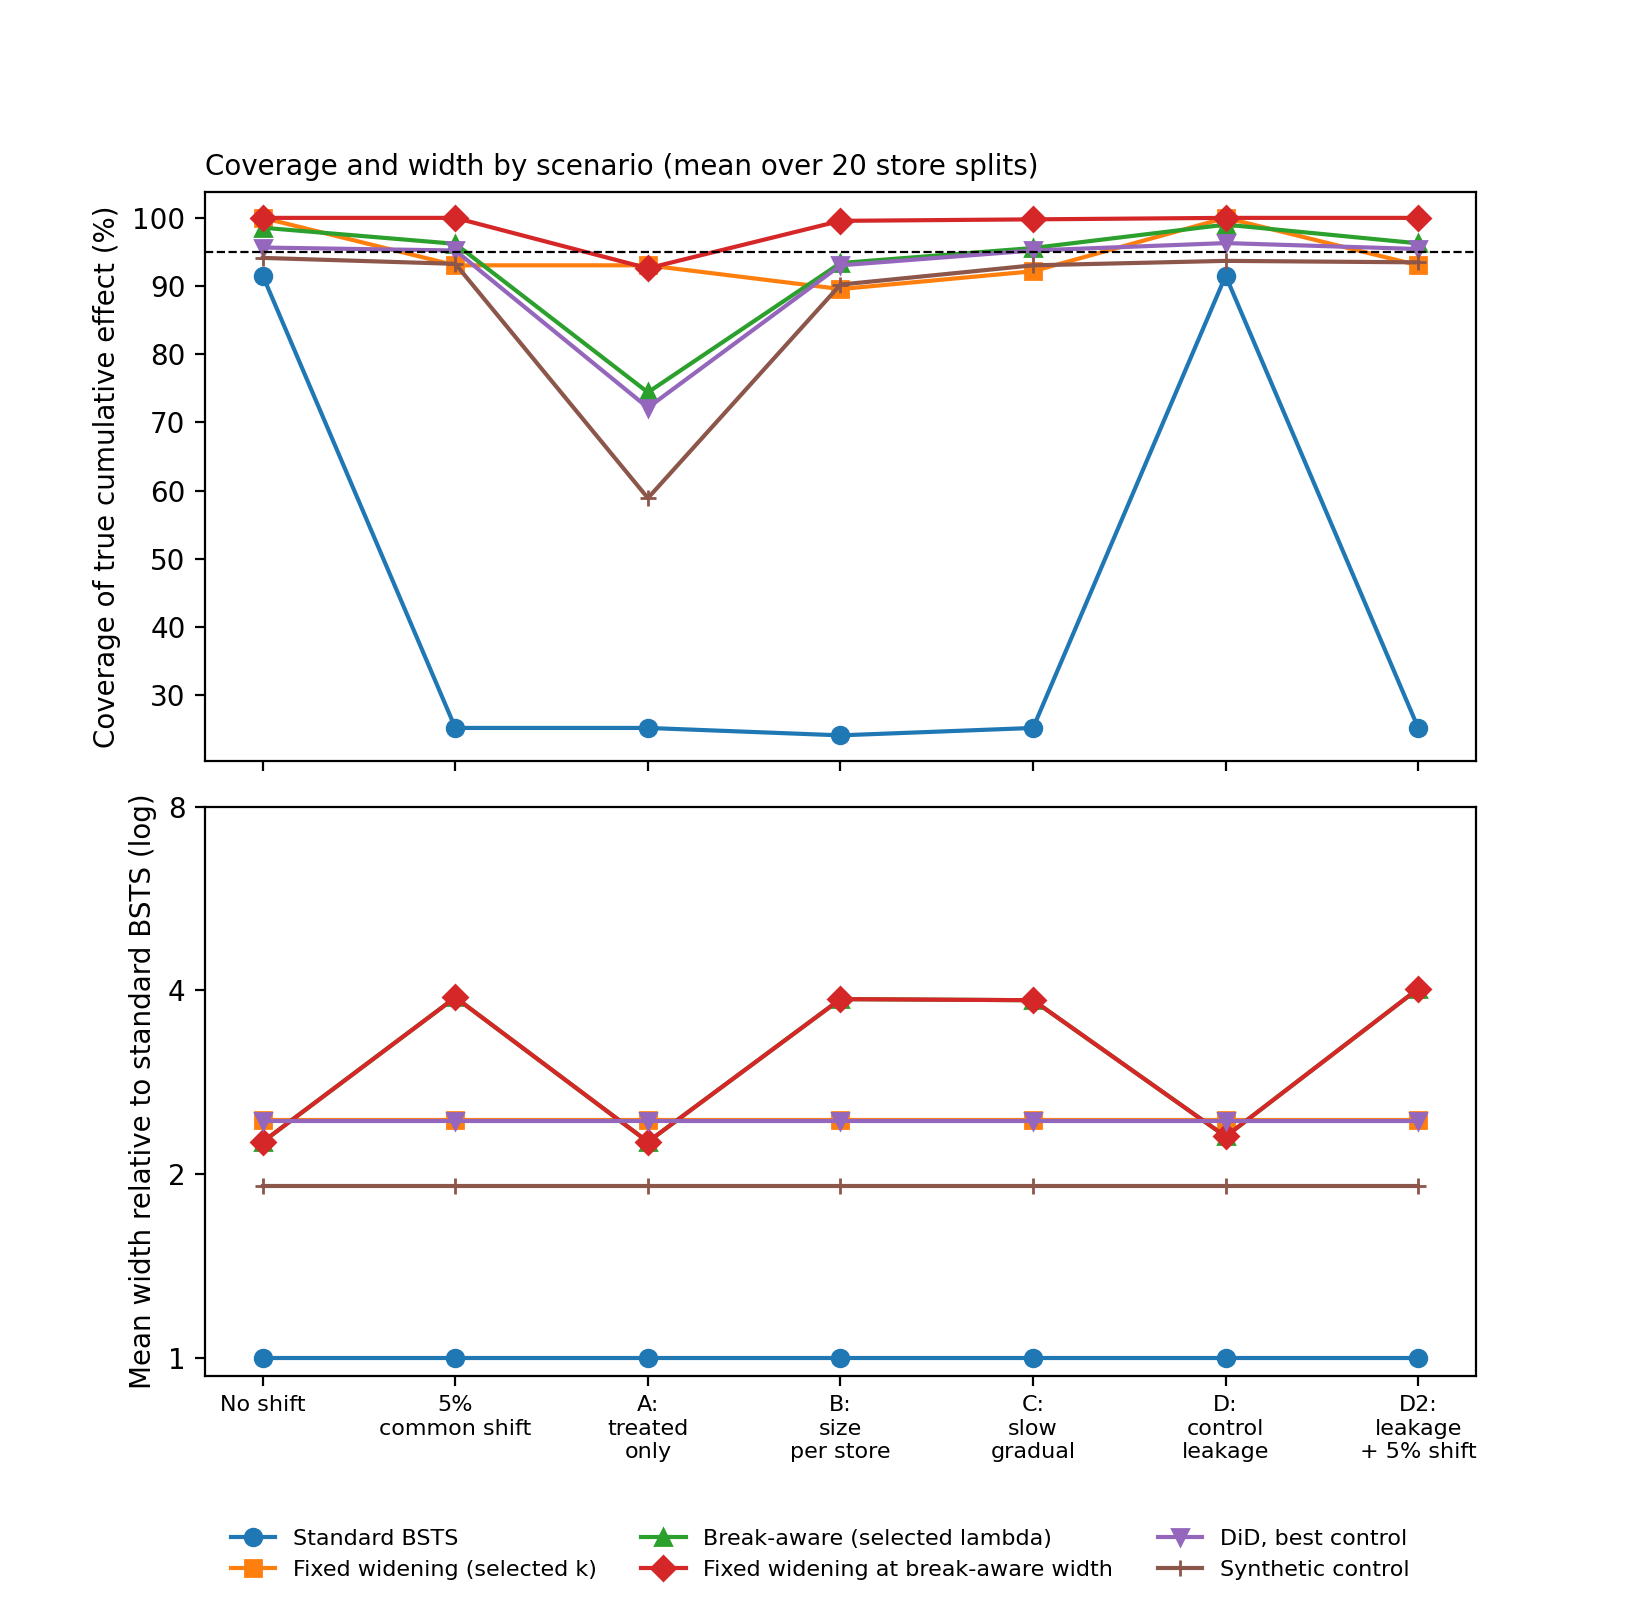

results/walmart/fig8_9_scenarios.png


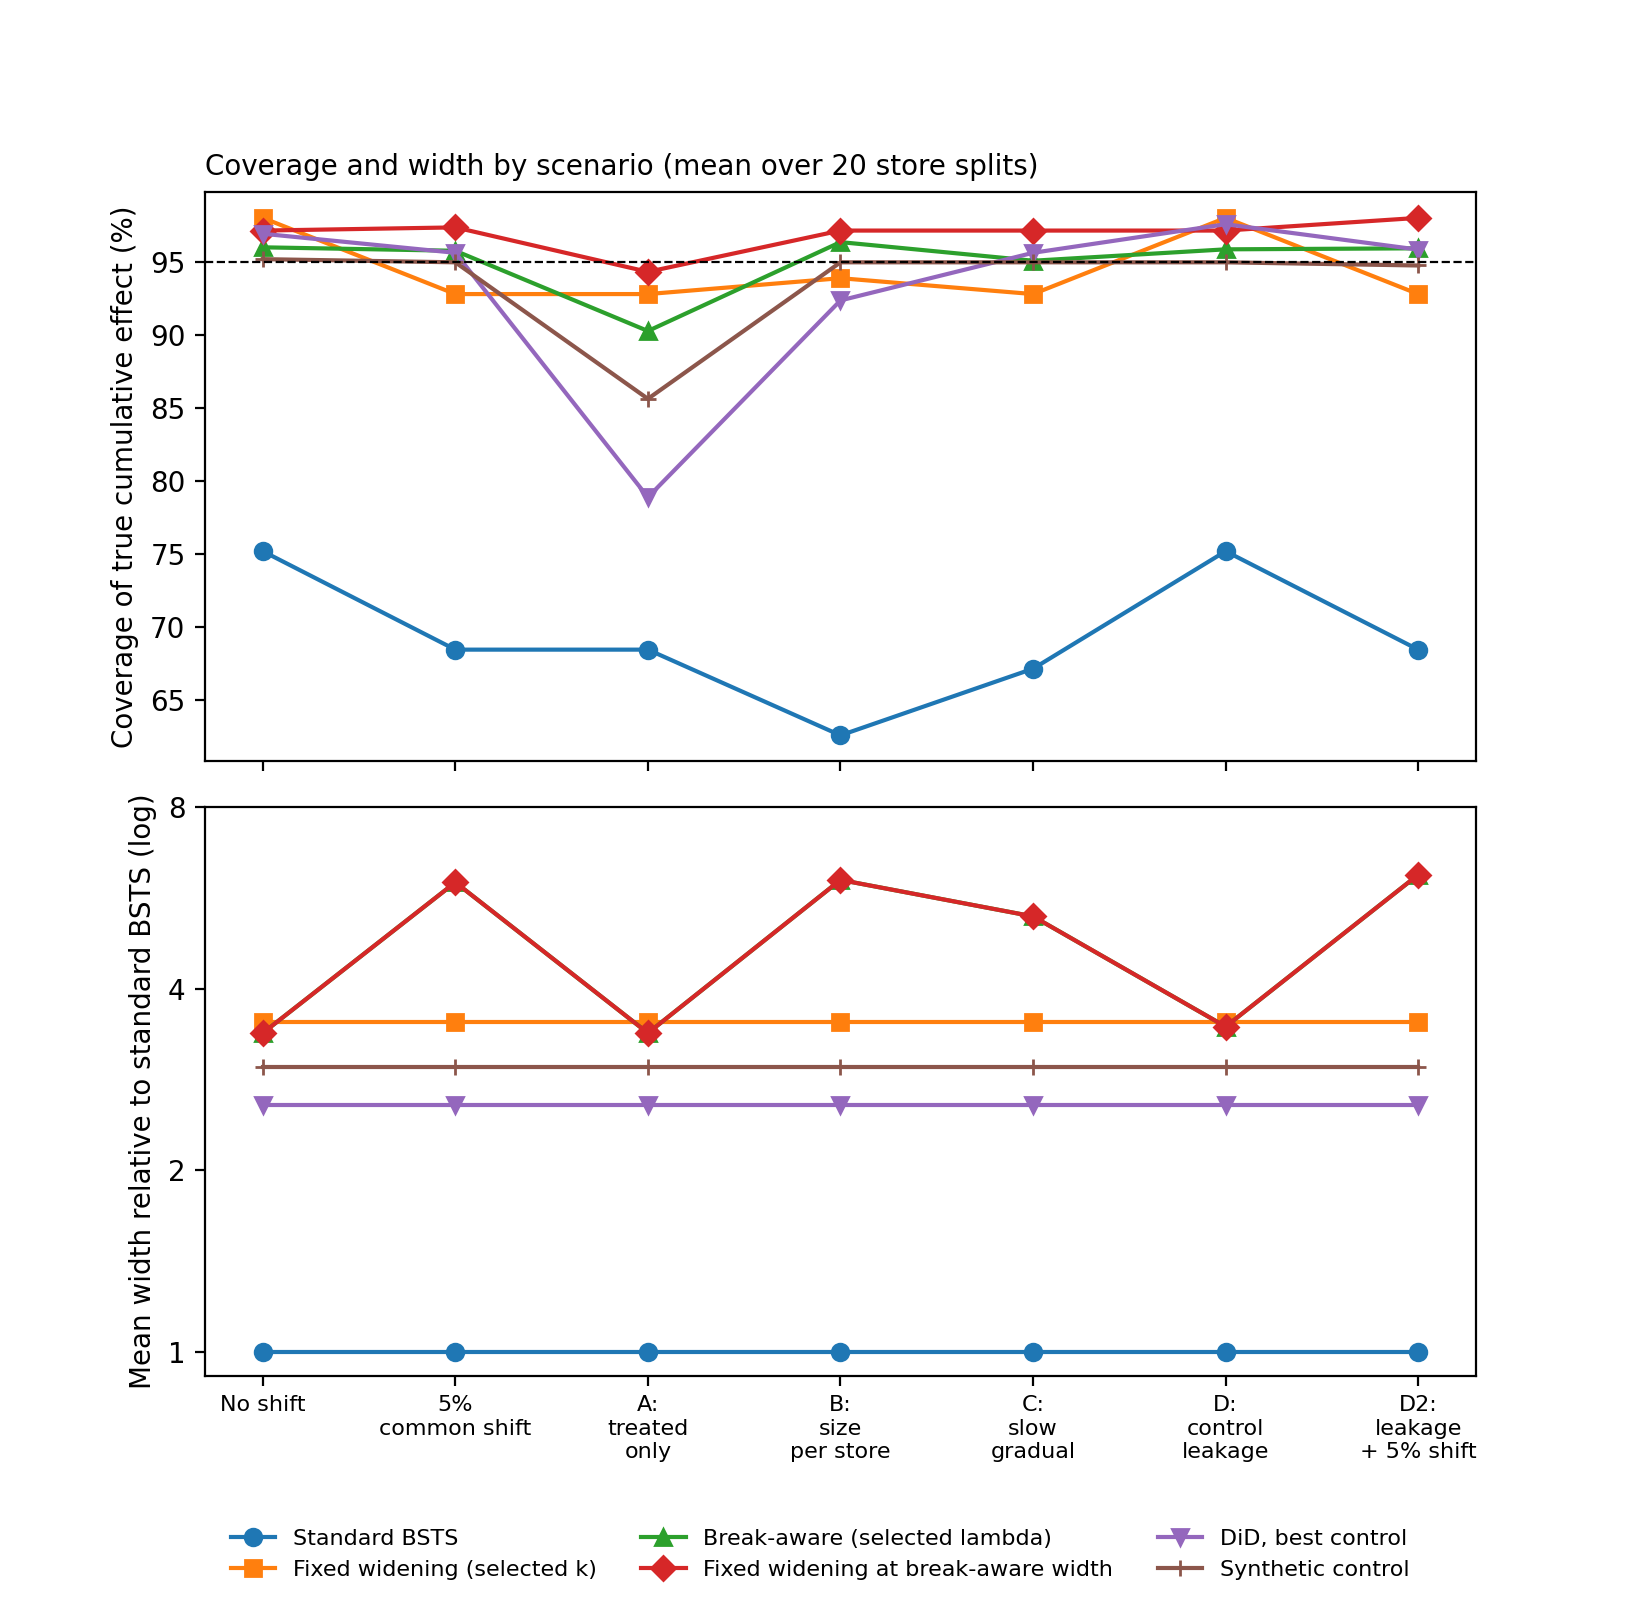

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import glob, shutil
from IPython.display import Image, display
for f in sorted(glob.glob("results*/**/fig8_9_scenarios.png", recursive=True)):
    print(f); display(Image(f))
folder = [d for d in glob.glob("results*") if os.path.isdir(d)][0]
shutil.make_archive("results_zip", "zip", folder)
files.download("results_zip.zip")